# Validating the `root.cms-combine` plug-in

This notebook validates `root.cms-combine`, the [CMS Combine](https://cms-analysis.github.io/HiggsAnalysis-CombinedLimit/)
backend of [`spey-roofit`](https://github.com/SpeysideHEP/spey-roofit).

A *datacard* is the input format of `combine`, the statistical tool of the CMS
collaboration, and is what CMS publishes when it publishes a likelihood. The plug-in does
not reimplement any of `combine`: it drives `combine`'s own `DatacardParser` and
`ShapeBuilder` in process, so the `RooFit` workspace is exactly the one
`text2workspace.py` writes, and then evaluates that workspace with the same machinery
that already backs `root.roofit` and `root.hs3`. What it adds is the part `combine` has
no interface for — a reader that says what the model *is* before it is compiled, and a
way to attach a signal of one's own to a published card.

The validation proceeds on four fronts:

1. **Against `spey`'s own likelihoods.** Datacards are written by hand so that the model
   `combine` builds from them is, term for term, one of `spey`'s built-in likelihoods.
   Every number then has to agree to the tolerance of the minimiser, not to a few per
   cent.
2. **Against two independent tools.** The same models are built with `pyhf`, through
   [`spey-pyhf`](https://github.com/SpeysideHEP/spey-pyhf), and with `HistFactory`,
   through `root.roofit`. Three implementations of one likelihood is a stronger statement
   than two.
3. **The distribution of the test statistic** over two thousand toys, against $\chi^2_1$
   and against the other backends, and the **expected exclusion** as a Brazilian plot.
4. **A published analysis**: the dijet angular search CMS-EXO-24-011, read from the
   datacards the collaboration released, including the limit on the ADD scale and a
   reinterpretation with an injected signal.

The material of section 5 is not committed to this repository. Fetch it with
`./cms-exo-24-011/download.sh`; everything else runs without it.

In [1]:
import json
import os
import sys
import time

import numpy as np
import spey
from spey.system.logger import disable_logging

import spey_roofit
from spey_roofit import DatacardInterpreter, compile_datacard, patch_datacard
from spey_roofit.combine import (
    SWAPPED_TWO_HYPOTHESIS_MODEL,
    TWO_HYPOTHESIS_MODEL,
    combine_modules,
    combine_options,
)


def find_repository(start=None):
    """Walk up from `start` until the directory holding pyproject.toml is found."""
    directory = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.exists(os.path.join(directory, "pyproject.toml")):
            return directory
        parent = os.path.dirname(directory)
        if parent == directory:
            raise RuntimeError("run this notebook from inside the repository")
        directory = parent


REPOSITORY = find_repository()
CMS = os.path.join(REPOSITORY, "cms-exo-24-011")
sys.path.insert(0, os.path.join(REPOSITORY, "tests"))

REFERENCE = os.path.join(
    CMS, "datacards", "input", "chi_datacard13TeV3_ADD12000_run2.txt"
)
CMS_AVAILABLE = os.path.exists(REFERENCE)

WORKDIR = os.path.join(CMS, "_generated")
os.makedirs(WORKDIR, exist_ok=True)

print("spey        ", spey.__version__)
print("spey-roofit ", spey_roofit.__version__)
print("ROOT        ", spey_roofit.manager.version)
print("combine     ", combine_modules().tools.__file__.split("site-packages/")[-1])
print(
    "CMS material",
    "available" if CMS_AVAILABLE else "missing (section 5 will be skipped)",
)

Spey - WARNING: An unstable version of Spey (0.2.8-b1) is being used. Latest stable version is 0.2.7.


spey         0.2.8-b1
spey-roofit  0.0.1


ROOT         6.36.04


combine      HiggsAnalysis/CombinedLimit/ModelTools.py
CMS material available


---
## 1. What a datacard looks like

A datacard is a text file. Its header declares the channels and what was observed in
each of them, its middle block declares one column per (channel, process) pair with the
expected yield of each, and its tail declares the systematic uncertainties as a table
over those columns. A `shapes` line points at the histograms when the analysis is
binned in something finer than a counting experiment.

The builders in `tests/combine_models.py` write such cards from scratch. Here is the twin
of `spey`'s `default.uncorrelated_background`: one channel, three bins, and an
`autoMCStats` directive, which is `combine`'s Barlow–Beeston-lite treatment of the Monte
Carlo uncertainty of the templates. With a threshold of zero every bin gets one nuisance
parameter $\beta_i$ with a unit Gaussian constraint and the expectation becomes
$\lambda_i = b_i + \mu s_i + \beta_i\sigma_i$ — exactly that backend's model.

`lnN`, the uncertainty one reaches for first in `combine`, would *not* be: it is
multiplicative, $b_i\kappa^{\theta}$, and has no counterpart among `spey`'s defaults. It
does have one in `pyhf`, which is used in section 2.3.

In [2]:
from combine_models import (
    log_normal_datacard,
    poisson_datacard,
    shape_datacard,
    uncorrelated_background_datacard,
)

background = [50.0, 60.0, 30.0]
signal = [12.0, 11.0, 5.0]
uncertainty = [3.0, 5.0, 2.0]
observed = [51.0, 48.0, 32.0]
kappas = [1.10, 1.20, 1.05]

uncorrelated = uncorrelated_background_datacard(
    WORKDIR, background, signal, observed, uncertainty
)
print(uncorrelated)

imax 1
jmax *
kmax *
--------------------
shapes * ch1 /Users/jackaraz/dev/MadAnalysis/spey-roofit/cms-exo-24-011/_generated/uncorrelated.root $PROCESS
bin ch1
observation 131
--------------------
bin ch1 ch1
process sig bkg
process 0 1
rate -1 -1
--------------------
ch1 autoMCStats 0 0 1



### The interpreter

`DatacardInterpreter` is the user-facing view of the card. It lists the channels, their
binning, the samples and their yields, and it does so *before* anything is compiled — the
templates are read through `combine`'s own `ShapeBuilder`, and the structure through its
own `DatacardParser`. No knowledge of `combine`, and none of `RooFit`, is needed to find
out what a published likelihood contains.

In [3]:
interpreter = DatacardInterpreter(uncorrelated)

print("channels and bins   :", interpreter.bin_map)
print("samples             :", interpreter.samples)
print("signal samples      :", interpreter.signal_samples)
print("nuisance parameters :", interpreter.nuisance_parameters or "none declared")
print("background yields   :", interpreter.expected_background_yields)
print("signal yields       :", interpreter.expected_signal_yields)
print("observed data       :", interpreter.observed_data)

channels and bins   : {'ch1': 3}
samples             : {'ch1': ['sig', 'bkg']}
signal samples      : {'ch1': ['sig']}
nuisance parameters : none declared
background yields   : {'ch1': [np.float64(50.0), np.float64(60.0), np.float64(30.0)]}
signal yields       : {'ch1': [np.float64(12.0), np.float64(11.0), np.float64(5.0)]}
observed data       : {'ch1': [np.float64(51.0), np.float64(48.0), np.float64(32.0)]}


### Compiling it

`compile_datacard` is `text2workspace.py`, driven in process. What comes out is an
ordinary `RooWorkspace` holding `combine`'s own objects — `ProcessNormalization`,
`FastVerticalInterpHistPdf2`, a `RooSimultaneous` over the channels — together with the
`RooStats::ModelConfig` that names the parameter of interest, the nuisance parameters and
the global observables.

Two small things are adjusted afterwards, both of them about reading the workspace rather
than about building it:

* `combine` lists only the *constrained* parameters as nuisance parameters, so a
  `rateParam` would float in the model but never be profiled by `spey`. Everything that
  floats is added to the set.
* the auxiliary measurements are given room around their constraints. `spey` normalises a
  constraint over its auxiliary measurement, and `combine` gives a `shape` parameter the
  range $[-4,4]$, which at $\theta=-1.5$ already cuts six parts in a thousand off the
  Gaussian. `combine` never notices, because it does not normalise its constraints at all.

In [4]:
workspace, model_config = compile_datacard(uncorrelated)

print("workspace    :", workspace.GetName())
print(
    "pdf          :", model_config.GetPdf().ClassName(), model_config.GetPdf().GetName()
)
print("POI          :", [v.GetName() for v in model_config.GetParametersOfInterest()])
print("nuisances    :", [v.GetName() for v in model_config.GetNuisanceParameters()])
print("global obs.  :", [v.GetName() for v in model_config.GetGlobalObservables()])
print("datasets     :", [d.GetName() for d in workspace.allData()])
print()
print("channel pdf  :", workspace.pdf("model_s").getPdf("ch1").ClassName())
print(
    "components   :",
    sorted({c.ClassName() for c in workspace.pdf("model_s").getComponents()}),
)

workspace    : w
pdf          : RooSimultaneous model_s
POI          : ['r']
nuisances    : ['prop_binch1_bin0', 'prop_binch1_bin1', 'prop_binch1_bin2']
global obs.  : ['prop_binch1_bin0_In', 'prop_binch1_bin1_In', 'prop_binch1_bin2_In']
datasets     : ['data_obs']

channel pdf  : RooProdPdf
components   : ['CMSHistErrorPropagator', 'CMSHistFunc', 'ProcessNormalization', 'RooGaussian', 'RooProdPdf', 'RooRealSumPdf', 'RooSimultaneous']


---
## 2. Exact comparison with `spey`'s own likelihoods

Each of the following cards is built so that the model `combine` makes of it is a
likelihood `spey` — or `pyhf`, or `HistFactory` — already implements. The comparison is
therefore not a sanity check with a loose tolerance; the numbers have to agree to the
tolerance of the minimiser.

### 2.1 A counting experiment without systematics

The simplest card there is: one single-bin channel per entry, a signal and a background
rate, and no systematics block at all. That is `default.poisson`,
$\mathcal{L}(\mu)=\prod_i \mathrm{Pois}(n_i\,|\,\mu s_i + b_i)$.

`combine` builds a card without `shapes` directives as a product of `RooPoisson` terms
over plain variables, which is the same likelihood but not a binned shape `spey` can
read; the plug-in therefore gives such a card one-bin templates first and lets `combine`
build the binned model of the very same product.

In [5]:
counting = poisson_datacard(background, signal, observed)

combine_poisson = spey.get_backend("root.cms-combine")(
    datacard=counting, analysis="combine"
)
spey_poisson = spey.get_backend("default.poisson")(
    signal_yields=signal, background_yields=background, data=observed, analysis="spey"
)

rows = []
for poi in (0.0, 0.5, 1.0, 2.0):
    ours = combine_poisson.likelihood(poi_test=poi)
    theirs = spey_poisson.likelihood(poi_test=poi)
    rows.append((poi, ours, theirs, ours - theirs))
print(f"{'mu':>5} {'root.cms-combine':>20} {'default.poisson':>20} {'difference':>14}")
for poi, ours, theirs, difference in rows:
    print(f"{poi:5.1f} {ours:20.12f} {theirs:20.12f} {difference:14.2e}")
print()
print(
    "muhat            : %.12f vs %.12f"
    % (combine_poisson.maximize_likelihood()[0], spey_poisson.maximize_likelihood()[0])
)
print(
    "95%% CL upper limit: %.12f vs %.12f"
    % (combine_poisson.poi_upper_limit(), spey_poisson.poi_upper_limit())
)

   mu     root.cms-combine      default.poisson     difference
  0.0       9.761447212161       9.761447212161       0.00e+00
  0.5      11.210449755834      11.210449755834      -2.84e-14
  1.0      13.777849985903      13.777849985903       0.00e+00
  2.0      21.567489535104      21.567489535104      -2.84e-14

muhat            : -0.281256430073 vs -0.281257315657


95% CL upper limit: 0.685659244256 vs 0.685659244256


### 2.2 Uncorrelated background: `autoMCStats`

The card of section 1, against `default.uncorrelated_background`. This is the comparison
that exercises the constraint model: three nuisance parameters, each with a unit Gaussian
constraint, each entering its own bin additively.

In [6]:
combine_uncorrelated = spey.get_backend("root.cms-combine")(
    datacard=uncorrelated, analysis="combine"
)
spey_uncorrelated = spey.get_backend("default.uncorrelated_background")(
    signal_yields=signal,
    background_yields=background,
    data=observed,
    absolute_uncertainties=uncertainty,
    analysis="spey",
)

print("parameters:", combine_uncorrelated.backend.model.parameter_names)
print()
print(
    f"{'mu':>5} {'root.cms-combine':>20} {'default.uncorrelated':>22} {'difference':>14}"
)
for poi in (0.0, 0.5, 1.0, 2.0):
    ours = combine_uncorrelated.likelihood(poi_test=poi)
    theirs = spey_uncorrelated.likelihood(poi_test=poi)
    print(f"{poi:5.1f} {ours:20.12f} {theirs:22.12f} {ours - theirs:14.2e}")
print()
print(
    "muhat              : %.10f vs %.10f"
    % (
        combine_uncorrelated.maximize_likelihood()[0],
        spey_uncorrelated.maximize_likelihood()[0],
    )
)
print(
    "exclusion CL at mu=1: %.10f vs %.10f"
    % (
        combine_uncorrelated.exclusion_confidence_level()[0],
        spey_uncorrelated.exclusion_confidence_level()[0],
    )
)
print(
    "95%% CL upper limit  : %.10f vs %.10f"
    % (combine_uncorrelated.poi_upper_limit(), spey_uncorrelated.poi_upper_limit())
)

parameters: ['r', 'prop_binch1_bin0', 'prop_binch1_bin1', 'prop_binch1_bin2']

   mu     root.cms-combine   default.uncorrelated     difference
  0.0      12.137952884012        12.137952817512       6.65e-08
  0.5      13.246697603280        13.246697317537       2.86e-07
  1.0      15.348572876957        15.348572896819      -1.99e-08
  2.0      22.047274017870        22.047274022211      -4.34e-09

muhat              : -0.2387186188 vs -0.2387243068
exclusion CL at mu=1: 0.9838873987 vs 0.9838874178


95% CL upper limit  : 0.7904797172 vs 0.7904795164


### 2.3 Log-normal rates, against `pyhf`

`lnN` scales a yield by $\kappa^{\theta}$. `pyhf` writes the same thing as a `normsys`:
its default interpolation is the piecewise power law, which for a symmetric
$\kappa^-=1/\kappa^+$ is $\kappa^{\theta}$ everywhere — and so is `combine`'s `AsymPow`.
The two are the same likelihood, reached from two unrelated implementations.

In [7]:
import spey_pyhf

spey_pyhf.manager.backend = (
    "numpy"  # jax picks Metal on Apple silicon, which has no float64
)

lognormal = log_normal_datacard(background, signal, observed, kappas)

channels, observations, patch = [], [], []
for index, (b, s, n, kappa) in enumerate(zip(background, signal, observed, kappas)):
    channels.append(
        {
            "name": f"ch{index}",
            "samples": [
                {
                    "name": "bkg",
                    "data": [b],
                    "modifiers": [
                        {
                            "name": f"norm{index}",
                            "type": "normsys",
                            "data": {"hi": kappa, "lo": 1.0 / kappa},
                        }
                    ],
                }
            ],
        }
    )
    observations.append({"name": f"ch{index}", "data": [n]})
    patch.append(
        {
            "op": "add",
            "path": f"/channels/{index}/samples/1",
            "value": {
                "name": "sig",
                "data": [s],
                "modifiers": [{"name": "mu", "type": "normfactor", "data": None}],
            },
        }
    )
pyhf_workspace = {
    "channels": channels,
    "observations": observations,
    "measurements": [{"name": "m", "config": {"poi": "mu", "parameters": []}}],
    "version": "1.0.0",
}

combine_lognormal = spey.get_backend("root.cms-combine")(
    datacard=lognormal, analysis="combine"
)
pyhf_lognormal = spey.get_backend("pyhf")(
    background_only_model=pyhf_workspace, signal_patch=patch, analysis="pyhf"
)

print(f"{'mu':>5} {'root.cms-combine':>20} {'pyhf':>20} {'difference':>14}")
for poi in (0.0, 0.5, 1.0, 2.0):
    ours = combine_lognormal.likelihood(poi_test=poi)
    theirs = pyhf_lognormal.likelihood(poi_test=poi)
    print(f"{poi:5.1f} {ours:20.12f} {theirs:20.12f} {ours - theirs:14.2e}")
print()
print(
    "95%% CL upper limit: %.10f vs %.10f"
    % (combine_lognormal.poi_upper_limit(), pyhf_lognormal.poi_upper_limit())
)

   mu     root.cms-combine                 pyhf     difference
  0.0      11.686992478442      11.686992450946       2.75e-08
  0.5      12.343916291117      12.343916193592       9.75e-08
  1.0      13.866991549124      13.866991563860      -1.47e-08
  2.0      19.271838168448      19.271838044762       1.24e-07



95% CL upper limit: 0.9712900885 vs 0.9712903453


### 2.4 Template morphing, against `HistFactory`

A `shape` uncertainty morphs the templates vertically. `combine` does it on the
*fractions* — every template is normalised to unit sum first — and carries the change of
the integral separately, as a log-normal factor on the rate. `HistFactory`'s `HistoSys`
morphs the absolute bin contents and carries nothing separately.

The two coincide whenever the varied templates have the *same integral* as the nominal
one: the log-normal factor is then unity, and the morphed fractions times the fixed rate
are the morphed contents. Building such a card and the matching `HistFactory` workspace
therefore compares `combine`'s interpolation against `ROOT`'s, term for term.

In [8]:
from toy_models import _build

shifts = [[4.0, -3.0, -1.0], [-2.0, 5.0, -3.0]]  # both sum to zero
shapes = shape_datacard(WORKDIR, background, signal, observed, shifts)

combine_shapes = spey.get_backend("root.cms-combine")(datacard=shapes, analysis="combine")
roofit_shapes = spey.get_backend("root.roofit")(
    workspace=_build(
        WORKDIR,
        "histosys",
        background,
        signal,
        observed,
        [np.asarray(shift) for shift in shifts],
    ),
    analysis="roofit",
)

print(
    "parameters:",
    combine_shapes.backend.model.parameter_names,
    "vs",
    roofit_shapes.backend.model.parameter_names,
)
print()
ours_logpdf = combine_shapes.backend.get_logpdf_func()
theirs_logpdf = roofit_shapes.backend.get_logpdf_func()
worst_yield = worst_logpdf = 0.0
for poi in (0.0, 1.0, 2.0):
    for theta in (-2.0, -0.7, 0.0, 0.5, 1.3):
        point = np.array([poi, theta, -0.5 * theta])
        combine_shapes.backend.model.set_parameters(point)
        roofit_shapes.backend.model.set_parameters(point)
        a = combine_shapes.backend.model.expected_yields()
        b = roofit_shapes.backend.model.expected_yields()
        worst_yield = max(worst_yield, float(np.max(np.abs(a / b - 1.0))))
        worst_logpdf = max(worst_logpdf, abs(ours_logpdf(point) - theirs_logpdf(point)))
print("largest relative difference in the expected yields: %.2e" % worst_yield)
print("largest difference in log L                       : %.2e" % worst_logpdf)

parameters: ['r', 'theta0', 'theta1'] vs ['mu', 'alpha_theta0', 'alpha_theta1']

largest relative difference in the expected yields: 3.33e-16
largest difference in log L                       : 7.46e-14


### 2.5 Asimov data

`spey` builds its Asimov datasets from `expected_data`, and since version 0.2.8 those
carry the profiled auxiliary measurements as well as the expected bin counts — equation
(25) of [arXiv:1007.1727](https://arxiv.org/abs/1007.1727). Getting the auxiliary half
wrong changes every expected limit, so it is worth its own comparison.

In [9]:
point = [1.0, 0.4, -0.2, 0.7]
ours = np.asarray(combine_uncorrelated.backend.expected_data(point))
theirs = np.asarray(spey_uncorrelated.backend.expected_data(point))

print("parameters      :", combine_uncorrelated.backend.model.parameter_names)
print("root.cms-combine:", np.round(ours, 10))
print("spey            :", np.round(theirs, 10))
print("largest difference: %.2e" % float(np.max(np.abs(ours - theirs))))

parameters      : ['r', 'prop_binch1_bin0', 'prop_binch1_bin1', 'prop_binch1_bin2']
root.cms-combine: [63.2 70.  36.4  0.4 -0.2  0.7]
spey            : [63.2 70.  36.4  0.4 -0.2  0.7]
largest difference: 0.00e+00


---
## 3. The distribution of the test statistic

Wilks' theorem says that the profile-likelihood test statistic
$t_\mu=-2\log\left[\mathcal{L}(\mu,\hat{\hat\theta})/\mathcal{L}(\hat\mu,\hat\theta)\right]$
follows a $\chi^2_1$ distribution when the data are generated at $\mu$. Two thousand
pseudo-experiments are drawn once, from the `root.cms-combine` sampler, and pushed
through all three implementations of the same model — `combine`, `spey`'s own likelihood
and `pyhf`. Because the toys are shared, any difference between the three curves is in
the likelihood and not in the random numbers.

The model is the uncorrelated-background one of section 2.2, written for `pyhf` with a
`histosys` whose up and down templates are $b_i\pm\sigma_i$.

`pyhf` could equally write it with a `staterror`, whose multiplicative $\gamma_i$ with a
Gaussian constraint of width $\sigma_i/b_i$ is the same additive shift — the cell below
checks that, and finds the two differ by exactly the Jacobian
$\sum_i\log(b_i/\sigma_i)$ of the change of variables. It is the wrong choice *here*
though, because the toys are shared: the auxiliary half of a data vector means
$\theta$-like measurements centred on zero for `combine` and for `spey`, and $\gamma$-like
ones centred on one for a `staterror`. Handing the same toy to both would be handing
`pyhf` the wrong auxiliary data.

In [10]:
from toy_models import uncorrelated_background_pyhf_workspace

pyhf_model, pyhf_patch = uncorrelated_background_pyhf_workspace(
    background, signal, observed, uncertainty
)
pyhf_uncorrelated = spey.get_backend("pyhf")(
    background_only_model=pyhf_model, signal_patch=pyhf_patch, analysis="pyhf"
)

print(f"{'mu':>5} {'root.cms-combine':>20} {'spey':>20} {'pyhf':>20}")
for poi in (0.0, 1.0, 2.0):
    print(
        f"{poi:5.1f} {combine_uncorrelated.likelihood(poi_test=poi):20.12f} "
        f"{spey_uncorrelated.likelihood(poi_test=poi):20.12f} "
        f"{pyhf_uncorrelated.likelihood(poi_test=poi):20.12f}"
    )
print()
print("parameters:", pyhf_uncorrelated.backend.config().parameter_names)

# the same model written the other way round, for the record
staterror_workspace = {
    "channels": [
        {
            "name": "ch1",
            "samples": [
                {
                    "name": "bkg",
                    "data": list(background),
                    "modifiers": [
                        {"name": "stat", "type": "staterror", "data": list(uncertainty)}
                    ],
                }
            ],
        }
    ],
    "observations": [{"name": "ch1", "data": list(observed)}],
    "measurements": [{"name": "m", "config": {"poi": "mu", "parameters": []}}],
    "version": "1.0.0",
}
staterror_patch = [
    {
        "op": "add",
        "path": "/channels/0/samples/1",
        "value": {
            "name": "sig",
            "data": list(signal),
            "modifiers": [{"name": "mu", "type": "normfactor", "data": None}],
        },
    }
]
staterror = spey.get_backend("pyhf")(
    background_only_model=staterror_workspace,
    signal_patch=staterror_patch,
    analysis="stat",
)
offsets = [
    staterror.likelihood(poi_test=poi) - combine_uncorrelated.likelihood(poi_test=poi)
    for poi in (0.0, 0.5, 1.0, 2.0)
]
print()
print("staterror minus combine, at four values of mu:", np.round(offsets, 10))
print(
    "the Jacobian sum_i log(b_i / sigma_i)        :",
    round(-float(np.sum(np.log(np.asarray(background) / np.asarray(uncertainty)))), 10),
)

   mu     root.cms-combine                 spey                 pyhf
  0.0      12.137952884012      12.137952817512      12.137952832441
  1.0      15.348572876957      15.348572896819      15.348572972492
  2.0      22.047274017870      22.047274022211      22.047274172516

parameters: ['theta0', 'theta1', 'theta2', 'mu']

staterror minus combine, at four values of mu: [-8.00636771 -8.00636789 -8.00636756 -8.00636757]
the Jacobian sum_i log(b_i / sigma_i)        : -8.0063675677


In [11]:
POI_TEST = 1.0
NUMBER_OF_TOYS = 2000

rng = np.random.default_rng(20240611)
np.random.seed(20240611)

sampler = combine_uncorrelated.backend.get_sampler(np.array([POI_TEST] + [0.0] * 3))
toys = sampler(NUMBER_OF_TOYS)
print("toys:", toys.shape, "(bins and auxiliary measurements)")

BACKENDS = {
    "root.cms-combine": combine_uncorrelated,
    "spey": spey_uncorrelated,
    "pyhf": pyhf_uncorrelated,
}


def test_statistic(model, data):
    """Profile-likelihood test statistic of one pseudo-experiment."""
    with disable_logging():
        fixed = model.likelihood(poi_test=POI_TEST, data=data)
        free = model.maximize_likelihood(data=data)[1]
    return 2.0 * (fixed - free)


start = time.time()
statistics = {}
for name, model in BACKENDS.items():
    statistics[name] = np.array([test_statistic(model, toy) for toy in toys])
print(
    "%d toys through %d backends in %.0f s"
    % (NUMBER_OF_TOYS, len(BACKENDS), time.time() - start)
)

toys: (2000, 6) (bins and auxiliary measurements)


2000 toys through 3 backends in 456 s


In [12]:
from scipy import stats

chi2_1 = stats.chi2(df=1)
print(f"{'':>18} {'mean':>9} {'median':>9} {'90th pct':>9}")
print(
    f"{'chi2_1':>18} {chi2_1.mean():9.4f} {chi2_1.median():9.4f} {chi2_1.ppf(0.9):9.4f}"
)
for name, values in statistics.items():
    print(
        f"{name:>18} {values.mean():9.4f} {np.median(values):9.4f} "
        f"{np.percentile(values, 90):9.4f}"
    )
print()
reference = statistics["root.cms-combine"]
for name, values in statistics.items():
    if name == "root.cms-combine":
        continue
    print(
        "largest |t_mu(root.cms-combine) - t_mu(%s)|: %.2e"
        % (name, float(np.max(np.abs(reference - values))))
    )
print()
for name, values in statistics.items():
    result = stats.kstest(values, chi2_1.cdf)
    print(
        "KS against chi2_1, %-16s D = %.4f, p = %.3f"
        % (name, result.statistic, result.pvalue)
    )

                        mean    median  90th pct
            chi2_1    1.0000    0.4549    2.7055


  root.cms-combine    1.0030    0.4385    2.8072
              spey    1.0030    0.4385    2.8072
              pyhf    1.0030    0.4385    2.8072

largest |t_mu(root.cms-combine) - t_mu(spey)|: 1.63e-06
largest |t_mu(root.cms-combine) - t_mu(pyhf)|: 2.33e-06

KS against chi2_1, root.cms-combine D = 0.0177, p = 0.551
KS against chi2_1, spey             D = 0.0177, p = 0.551
KS against chi2_1, pyhf             D = 0.0177, p = 0.551


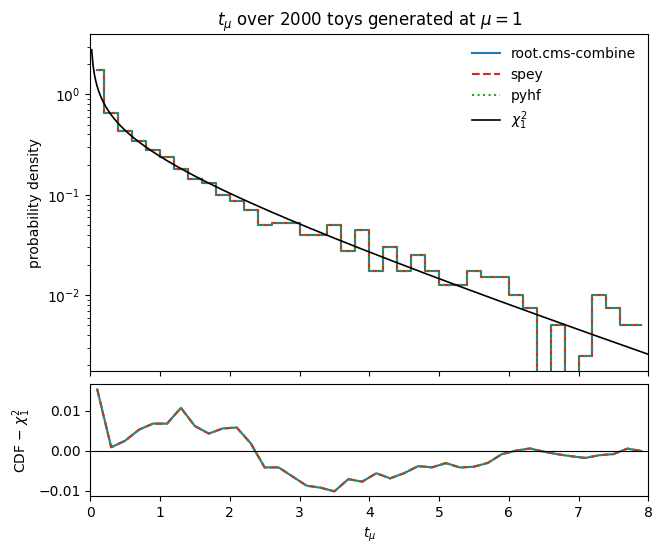

In [13]:
import matplotlib.pyplot as plt

fig, (upper, lower) = plt.subplots(
    2,
    1,
    figsize=(7.2, 6.0),
    height_ratios=[3, 1],
    sharex=True,
    gridspec_kw={"hspace": 0.06},
)

edges = np.linspace(0.0, 8.0, 41)
centres = 0.5 * (edges[1:] + edges[:-1])
styles = {
    "root.cms-combine": ("#1f77b4", "-"),
    "spey": ("#d62728", "--"),
    "pyhf": ("#2ca02c", ":"),
}

for name, values in statistics.items():
    colour, style = styles[name]
    counts, _ = np.histogram(values, bins=edges, density=True)
    upper.step(centres, counts, where="mid", color=colour, linestyle=style, label=name)

grid = np.linspace(0.02, 8.0, 400)
upper.plot(grid, chi2_1.pdf(grid), color="black", lw=1.2, label=r"$\chi^2_1$")
upper.set_yscale("log")
upper.set_ylabel("probability density")
upper.set_title(
    r"$t_\mu$ over %d toys generated at $\mu=%.0f$" % (NUMBER_OF_TOYS, POI_TEST)
)
upper.legend(frameon=False)

for name, values in statistics.items():
    colour, style = styles[name]
    empirical = np.array([np.mean(values <= edge) for edge in centres])
    lower.plot(centres, empirical - chi2_1.cdf(centres), color=colour, linestyle=style)
lower.axhline(0.0, color="black", lw=0.8)
lower.set_xlabel(r"$t_\mu$")
lower.set_ylabel(r"CDF $-$ $\chi^2_1$")
lower.set_xlim(0.0, 8.0)

plt.show()

---
## 4. Expected exclusion: the Brazilian plot

The other standard picture: the expected $\mathrm{CL}_s$ as a function of the signal
strength, with its $\pm1\sigma$ and $\pm2\sigma$ bands, and the observed curve on top.
Drawing it with all three backends and taking the difference is a test of the whole
chain — Asimov data, test statistic, asymptotic formulae — rather than of the likelihood
alone.

In [14]:
SCAN = np.linspace(0.05, 1.6, 26)

start = time.time()
curves = {}
for name, model in BACKENDS.items():
    with disable_logging():
        expected = np.array(
            [
                model.exclusion_confidence_level(
                    poi_test=float(poi), expected=spey.ExpectationType.aposteriori
                )
                for poi in SCAN
            ]
        )
        observed = np.array(
            [model.exclusion_confidence_level(poi_test=float(poi))[0] for poi in SCAN]
        )
    curves[name] = {"expected": expected, "observed": observed}
print(
    "%d points through %d backends in %.0f s"
    % (len(SCAN), len(BACKENDS), time.time() - start)
)

for name, model in BACKENDS.items():
    with disable_logging():
        limit = model.poi_upper_limit(expected=spey.ExpectationType.aposteriori)
    print("%-18s expected 95%% CL upper limit on mu: %.6f" % (name, limit))

26 points through 3 backends in 18 s


root.cms-combine   expected 95% CL upper limit on mu: 0.948186


spey               expected 95% CL upper limit on mu: 0.948185


pyhf               expected 95% CL upper limit on mu: 0.948194


In [15]:
reference = curves["root.cms-combine"]
for name, curve in curves.items():
    if name == "root.cms-combine":
        continue
    print(
        "largest |expected CLs difference| vs root.cms-combine, %-5s: %.2e"
        % (name, float(np.max(np.abs(curve["expected"] - reference["expected"]))))
    )
    print(
        "largest |observed CLs difference| vs root.cms-combine, %-5s: %.2e"
        % (name, float(np.max(np.abs(curve["observed"] - reference["observed"]))))
    )

largest |expected CLs difference| vs root.cms-combine, spey : 6.04e-06
largest |observed CLs difference| vs root.cms-combine, spey : 2.15e-06
largest |expected CLs difference| vs root.cms-combine, pyhf : 7.38e-06
largest |observed CLs difference| vs root.cms-combine, pyhf : 1.80e-06


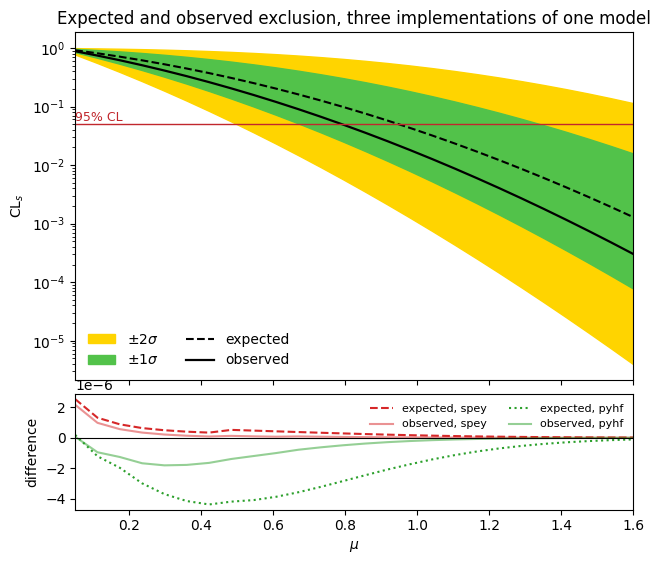

In [16]:
fig, (upper, lower) = plt.subplots(
    2,
    1,
    figsize=(7.2, 6.2),
    height_ratios=[3, 1],
    sharex=True,
    gridspec_kw={"hspace": 0.06},
)

expected = 1.0 - reference["expected"]  # CLs, not the exclusion confidence level
upper.fill_between(
    SCAN, expected[:, 0], expected[:, 4], color="#ffd400", label=r"$\pm2\sigma$"
)
upper.fill_between(
    SCAN, expected[:, 1], expected[:, 3], color="#52c24a", label=r"$\pm1\sigma$"
)
upper.plot(SCAN, expected[:, 2], color="black", linestyle="--", label="expected")
upper.plot(SCAN, 1.0 - reference["observed"], color="black", lw=1.6, label="observed")
upper.axhline(0.05, color="#c1272d", lw=1.0)
upper.text(SCAN[0], 0.057, r"95% CL", color="#c1272d", fontsize=9)
upper.set_yscale("log")
upper.set_ylabel(r"$\mathrm{CL}_s$")
upper.set_title("Expected and observed exclusion, three implementations of one model")
upper.legend(frameon=False, ncol=2)

for name, curve in curves.items():
    if name == "root.cms-combine":
        continue
    colour, style = styles[name]
    lower.plot(
        SCAN,
        curve["expected"][:, 2] - reference["expected"][:, 2],
        color=colour,
        linestyle=style,
        label=f"expected, {name}",
    )
    lower.plot(
        SCAN,
        curve["observed"] - reference["observed"],
        color=colour,
        linestyle="-",
        alpha=0.5,
        label=f"observed, {name}",
    )
lower.axhline(0.0, color="black", lw=0.8)
lower.set_xlabel(r"$\mu$")
lower.set_ylabel("difference")
lower.legend(frameon=False, fontsize=8, ncol=2)
lower.set_xlim(SCAN[0], SCAN[-1])

plt.show()

---
## 5. A published analysis: CMS dijet angular distributions

[CMS-EXO-24-011](https://repository.cern/records/wqfww-n3j76) measures the dijet angular
variable $\chi=\exp|y_1-y_2|$ in eight bins of the dijet mass and searches it for new
physics. The collaboration released the full statistical model as datacards, one per
signal model and mass point.

The card is a *two hypothesis* fit rather than the usual signal-plus-background one. Each
mass bin carries two signal processes, `QCDADD<Λ>` — QCD plus the ADD contribution — and
`QCDADD<Λ>_ALT` — QCD alone — normalised to the same number of events, plus a dummy
background of $10^{-20}$ events that `combine` requires. A parameter $x$ interpolates
between them: $x=1$ is QCD+BSM, $x=0$ is the Standard Model. The BSM signal is therefore
a pure *shape*, and the mass scale $\Lambda$ is excluded when the upper limit on $x$
falls below one.

Run `./cms-exo-24-011/download.sh` first; this section skips itself otherwise.

In [17]:
if not CMS_AVAILABLE:
    print("The CMS datacards are not available; run ./cms-exo-24-011/download.sh")
else:
    published = DatacardInterpreter(REFERENCE)
    print(published)
    print()
    published.summary(max_channels=2, show_samples=True)

DatacardInterpreter(8 channels, 96 bins, 149 systematics)

CMS Combine datacard (shape)
  channels            : 8
  bins                : 96
  processes           : QCDADD12000, QCDADD12000_ALT, QCD
  signal processes    : QCDADD12000, QCDADD12000_ALT
  nuisance parameters : 149 (149 shape)
  rate parameters     : 0
  autoMCStats         : none

  bin0 (12 bins)
      observed   : [1.077e+05, 8.899e+04, 8.56e+04, 8.56e+04, 8.675e+04, 8.797e+04, ...]
      background : [9.104e-20, 7.627e-20, 7.532e-20, 7.632e-20, 7.864e-20, 8.01e-20, ...]
      signal     : [2.041e+05, 1.691e+05, 1.658e+05, 1.69e+05, 1.722e+05, 1.745e+05, ...]
        - QCDADD12000 (signal): [1.02e+05, 8.457e+04, 8.288e+04, 8.452e+04, 8.61e+04, 8.726e+04, ...]
        - QCDADD12000_ALT (signal): [1.02e+05, 8.457e+04, 8.288e+04, 8.452e+04, 8.61e+04, 8.726e+04, ...]
        - QCD: [9.104e-20, 7.627e-20, 7.532e-20, 7.632e-20, 7.864e-20, 8.01e-20, ...]
  bin1 (12 bins)
      observed   : [2.256e+04, 1.837e+04, 1.827e+04, 1.

### What the interpreter shows

Three things are worth pointing out, all of them read from the card rather than assumed.

The first is the *renaming*. The card ends with sixty `nuisance edit rename` lines —
`jes1` becomes `CMS_scale_j_AbsoluteScale`, and so on — which the collaboration appends
long after the templates were written. `combine` renames the parameter but keeps looking
the histograms up under the old name, so both spellings are live at once.

The second is that the highest mass channel is *ragged*: its data and both its signal
templates are rebinned to five bins, while the negligible `QCD` dummy still has twelve.
`combine` pads the short templates, and the interpreter reports the padded length.

The third is that the two hypotheses share their normalisation exactly, which is what
makes this a shape-only search.

In [18]:
if CMS_AVAILABLE:
    names = published.nuisance_parameters
    print("nuisance parameters :", len(names))
    print("renamed             :", sum(1 for n in names if n.startswith("CMS_")))
    print("examples            :", ", ".join(names[:2] + names[24:27]))
    print()
    print("bins per channel    :", published.bin_map)
    print("bin7 observed       :", published.observed_data["bin7"])
    print()
    yields = published.sample_yields("bin7")["bin7"]
    primary = np.asarray(yields["QCDADD12000"])
    alternative = np.asarray(yields["QCDADD12000_ALT"])
    print("QCD+BSM total       : %.6f" % primary.sum())
    print("QCD total           : %.6f" % alternative.sum())
    print(
        "largest bin-by-bin difference: %.3f events"
        % np.max(np.abs(primary - alternative))
    )

nuisance parameters : 149
renamed             : 41
examples            : simulation_gen_model, CMS_res_j_tails, CMS_scale_j_AbsoluteScale, CMS_scale_j_AbsoluteMPFBias, CMS_scale_j_SinglePionHCAL

bins per channel    : {'bin0': 12, 'bin1': 12, 'bin2': 12, 'bin3': 12, 'bin4': 12, 'bin5': 12, 'bin6': 12, 'bin7': 12}
bin7 observed       : [np.float64(14.0), np.float64(11.0), np.float64(5.0), np.float64(10.0), np.float64(10.0), 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]

QCD+BSM total       : 50.000000
QCD total           : 50.000000
largest bin-by-bin difference: 6.017 events


### Compiling it, and which hypothesis $x$ selects

`combine` ships the two hypothesis model as
`HiggsAnalysis.CombinedLimit.HiggsJPC:twoHypothesisHiggs`. It scales the process whose
name carries the `ALT` marker by $x$ — which for this card is QCD *alone*. The record
states the opposite convention, $x=1$ for QCD+BSM, and used a modified copy of the model
to get it.

That distinction is not cosmetic here. `spey` defines its background as the model at
$\mu=0$ and its signal as the difference to $\mu=1$, so the two conventions test opposite
hypotheses. `spey_roofit.physics_models:twoHypothesisHiggs` is the stock model with the
two exchanged, and is what reproduces the published one; both are shown below so that the
mirror symmetry is visible rather than asserted.

In [19]:
if CMS_AVAILABLE:
    start = time.time()
    cms = spey.get_backend("root.cms-combine")(
        datacard=REFERENCE,
        physics_model=SWAPPED_TWO_HYPOTHESIS_MODEL,
        analysis="cms-exo-24-011",
    )
    stock = spey.get_backend("root.cms-combine")(
        datacard=REFERENCE, physics_model=TWO_HYPOTHESIS_MODEL, analysis="stock"
    )
    print("compiled two workspaces in %.1f s" % (time.time() - start))

    data = cms.backend.model
    print("bins                :", data.nbins)
    print("nuisance parameters :", data.naux)
    print("parameter of interest:", data.poi.GetName())
    print("channel pdf         :", data.pdf.ClassName())
    print()
    background, signal = cms.backend._background_and_signal()
    _, mirrored = stock.backend._background_and_signal()
    first = slice(84, 90)  # the first bins of the highest mass channel
    print("background (x=0), bin7:", np.round(background[first], 3))
    print("signal (x=1 - x=0)    :", np.round(signal[first], 3))
    print("the same with combine's own model:", np.round(mirrored[first], 3))
    print("the two are mirror images:", np.allclose(signal, -mirrored, atol=1e-6))

compiled two workspaces in 3.4 s
bins                : 96
nuisance parameters : 149
parameter of interest: x
channel pdf         : RooSimultaneous

background (x=0), bin7: [ 6.848  9.383  9.482 10.343 13.944  0.   ]
signal (x=1 - x=0)    : [ 6.017  1.007 -1.172 -2.296 -3.556  0.   ]
the same with combine's own model: [-6.017 -1.007  1.172  2.296  3.556  0.   ]
the two are mirror images: True


### The fit

No excess is reported by the paper, so the mixing parameter has to come out compatible
with the Standard Model, and the QCD+BSM hypothesis at $\Lambda=12$ TeV has to be
excluded.

In [20]:
if CMS_AVAILABLE:
    start = time.time()
    with disable_logging():
        fitted, nll = cms.maximize_likelihood()
        exclusion = cms.exclusion_confidence_level(poi_test=1.0)[0]
    print("xhat                       : %.6f" % fitted)
    print("-log L at the best fit     : %.6f" % nll)
    print("exclusion CL of x = 1      : %.6f" % exclusion)
    print("i.e. CLs                   : %.3e" % (1.0 - exclusion))
    print("(%.0f s over %d parameters)" % (time.time() - start, cms.backend.model.npar))

xhat                       : 0.141291
-log L at the best fit     : 573.565045
exclusion CL of x = 1      : 0.999998
i.e. CLs                   : 2.085e-06
(21 s over 150 parameters)


### Against a pure `RooFit` workflow

The fit above is `spey`'s. The same card can also be taken through the workflow CMS itself
starts from — `text2workspace.py` on the command line, with the swapped two-hypothesis
model — and the workspace it writes handed to `RooStats` directly. That workspace is
`combine`'s own: `combine`'s ranges, no `spey-roofit` code anywhere.

One option is needed, `--no-optimize-pdfs`. By default `combine` writes optimised pdfs —
`SimpleGaussianConstraint` and the like — meant for its own minimisation code; handed to
`RooStats`' asymptotic calculator, that workspace gives wrong expected bands, a median
expected limit of 0.75 instead of about 0.35 on this card. With the option,
`combine` builds the same likelihood out of plain `RooFit` classes. From that workspace the
reference computes

* the **Brazilian plot** — observed and expected $\mathrm{CL}_s$ with the $\pm1\sigma$ and
  $\pm2\sigma$ bands — with `RooStats::HypoTestInverter` driving an `AsymptoticCalculator`
  with the one-sided $\tilde q_\mu$, the configuration of `StandardHypoTestInvDemo.C`;
* the **$\chi^2$ curve** — the profile likelihood ratio $-2\Delta\log\mathcal{L}(\mu)$ —
  with `RooMinimizer` and `Minuit2` on the negative log-likelihood `createNLL` builds from
  the `ModelConfig`.

`spey` then computes the same two curves on the same grid, with its defaults: $\tilde q_\mu$,
and expected bands from the post-fit (`aposteriori`) Asimov data, which is what `RooStats`
uses as well.

The reference runs in a separate Python process that imports neither `spey` nor
`spey-roofit` (`tests/roostats_reference.py`). That is not a formality: `ROOT` returns the
*same* `RooWorkspace` when a file that is already open is read again, so a reference computed
in this process would share its parameters, ranges and caches with the `spey` model.

Finally, `spey`'s log-likelihood is evaluated at the parameters `RooFit`'s minimiser found.
That separates the two things that could make the curves differ: the likelihood, and the
minimiser.

The parameter of interest is the mixing parameter $x$, which the physics model keeps in
$[0,1]$; the scan stays inside it. $x=1$ is the QCD+ADD hypothesis.

In [ ]:
from roostats_reference import (
    brazil_plot,
    chi2_plot,
    run_reference,
    spey_asymptotic_scan,
    spey_likelihood_at,
    spey_profile_scan,
    summarise,
)

import subprocess

if CMS_AVAILABLE:
    compiled = os.path.join(WORKDIR, "ADD12000_text2workspace.root")
    subprocess.run(
        [
            sys.executable,
            os.path.join(os.path.dirname(sys.executable), "text2workspace.py"),
            "-P",
            SWAPPED_TWO_HYPOTHESIS_MODEL,
            "--no-optimize-pdfs",
            REFERENCE,
            "-o",
            compiled,
        ],
        check=True,
        capture_output=True,
    )

    CLS_GRID = np.linspace(0.05, 1.0, 20)  # uniform: HypoTestInverter's fixed scan
    PROFILE_GRID = np.linspace(0.0, 0.8, 17)

    reference_cls, reference_profile = run_reference(
        compiled,
        cls_grid=CLS_GRID,
        profile_grid=PROFILE_GRID,
        libraries=["libHiggsAnalysisCombinedLimit"],
    )
    with disable_logging():
        spey_cls = spey_asymptotic_scan(cms, CLS_GRID)
        spey_profile = spey_profile_scan(cms, PROFILE_GRID)
        spey_at_roofit = spey_likelihood_at(cms, reference_profile)

    summarise(reference_cls, spey_cls, reference_profile, spey_profile, spey_at_roofit)

95% CL upper limit       RooStats  (its own)       spey
observed                   0.4490     0.4490     0.4490
expected -2 sigma          0.1906     0.1906     0.1908
expected -1 sigma          0.2532     0.2532     0.2536
expected median            0.3544     0.3544     0.3550
expected +1 sigma          0.4983     0.4983     0.4989
expected +2 sigma          0.6798     0.6798     0.6806
(limits read off the scan by linear interpolation; nan when the scan does
 not cross 0.05. 'its own' is HypoTestInverterResult's interpolation.)

largest |CLs(spey) - CLs(RooStats)| over the scan:
  observed          2.64e-04
  expected -2 sigma  5.16e-04
  expected -1 sigma  5.85e-04
  expected +0 sigma  6.74e-04
  expected +1 sigma  8.93e-04
  expected +2 sigma  1.22e-03

best fit             RooFit 0.132164   spey 0.131937
largest |-2 Delta log L| difference over the profile scan:
  spey's own fits                       7.77e-03
  spey's likelihood at RooFit's points  9.09e-03

wall-clock: RooStats

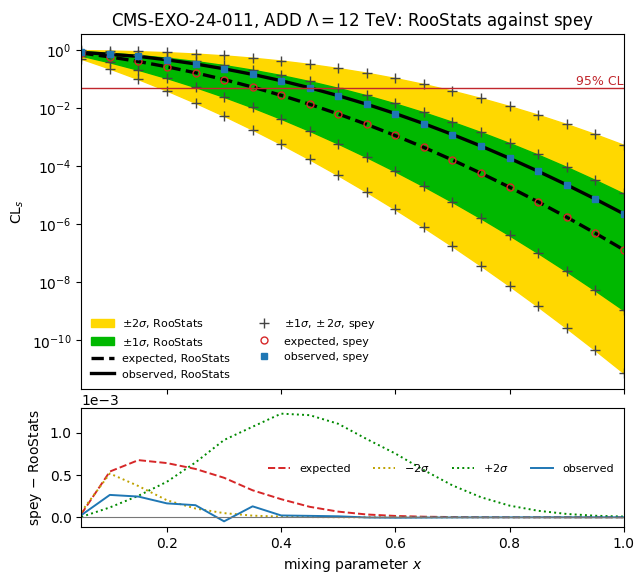

In [ ]:
if CMS_AVAILABLE:
    brazil_plot(
        reference_cls,
        spey_cls,
        r"CMS-EXO-24-011, ADD $\Lambda=12$ TeV: RooStats against spey",
        poi_label=r"mixing parameter $x$",
        log=True,
    )
    plt.show()

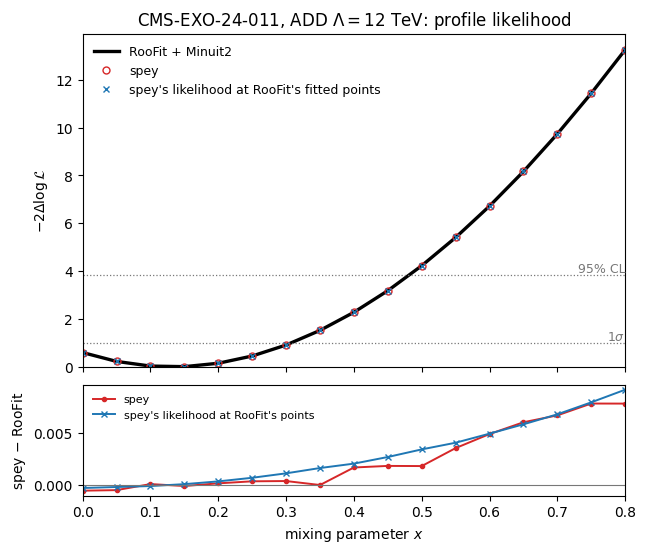

In [ ]:
if CMS_AVAILABLE:
    chi2_plot(
        reference_profile,
        spey_profile,
        r"CMS-EXO-24-011, ADD $\Lambda=12$ TeV: profile likelihood",
        poi_label=r"mixing parameter $x$",
        spey_at_reference=spey_at_roofit,
    )
    plt.show()

**The two plots, read together.** The two workflows agree. Every one of the six upper limits
on $x$ — observed, median and the four band edges — matches to $10^{-3}$: the observed limit
is 0.449 in both, the median expected 0.354 and 0.355. No $\mathrm{CL}_s$ anywhere in the
scan differs by more than $1.2\times10^{-3}$, and the best fits are 0.1322 and 0.1319.

The $\chi^2$ curves agree to $8\times10^{-3}$, and the blue crosses show where that remainder
comes from: `spey`'s log-likelihood, evaluated at the very parameters `RooFit` fitted,
differs from `RooFit`'s by the same amount, growing smoothly as $x$ moves away from its best
fit. That is a difference in the likelihood, not in the minimiser, and it is of the size the
plug-in's one deliberate change to the workspace produces: it widens the ranges of the
auxiliary measurements, which `combine` truncates at $\pm4$ and which therefore cut a few
parts in a thousand off a constraint once its nuisance parameter is displaced (section 1).

Two things had to be right for this agreement, one on each side. On the reference side,
`text2workspace.py` needs `--no-optimize-pdfs`, as explained above. On the `spey` side, the
plug-in evaluates the likelihood with `RooFit`'s bin-by-bin offset. Without it, the `RooFit`
negative log-likelihood of this card is of order $10^{7}$ — a data-dependent constant — so a
single evaluation is good only to a few parts in $10^{9}$, the finite-difference gradients
`spey` relies on lose their first significant digit, and its fits of these 149 parameters
stop short of the minimum.

### The limit on the ADD scale

The record publishes one card per mass point. Scanning them and asking for the exclusion
confidence level of $x=1$ at each gives the exclusion as a function of $\Lambda$, and the
crossing of the 95% line is the limit on the ADD scale. The scan runs over the ADD cards,
which takes a few minutes.

Two things about the scan are worth knowing in advance. The 20 TeV card of the release
points at a template file the archive does not contain, so it is skipped. And the curve is
not monotonic above 14 TeV: the ADD templates are generated per mass point and the
difference between the two hypotheses there is a few events out of fifty, so the
statistical fluctuations of the templates themselves show up in the limit. The crossing is
therefore taken as the first one from below rather than by interpolating the whole curve.

In [24]:
import glob
import re

candidates = sorted(
    glob.glob(os.path.join(CMS, "datacards", "ADD", "chi_datacard13TeV3_ADD*_run2.txt"))
)

# The 20 TeV card of the release points at a template file that was not shipped
# with it; every other card finds its own. Reading each one first is cheaper
# than discovering it halfway through the scan.
ADD, SCALES, SKIPPED = [], [], []
for path in candidates:
    scale = int(re.search(r"ADD(\d+)_run2", path).group(1)) / 1000.0
    try:
        DatacardInterpreter(path).bin_map
    except Exception as error:
        SKIPPED.append((scale, str(error).split("\n")[0]))
        continue
    ADD.append(path)
    SCALES.append(scale)

print("mass points  :", SCALES if ADD else "not unpacked; run ./download.sh")
for scale, reason in SKIPPED:
    print("skipping %g TeV: %s" % (scale, reason[:100]))

mass points  : [10.0, 11.0, 12.0, 13.0, 14.0, 15.0, 16.0, 17.0, 18.0, 19.0, 9.0]
skipping 20 TeV: Failed to open file /data/dust/user/hinzmann/dijetangular/CMSSW_8_1_0/src/cmsusercode/chi_analysis/v


Error in <TFile::TFile>: file /data/dust/user/hinzmann/dijetangular/CMSSW_8_1_0/src/cmsusercode/chi_analysis/versions/run2ULNNLO_m2/datacard_shapelimit13TeV_GENnp-32-run2_chi.root does not exist


In [25]:
if CMS_AVAILABLE and ADD:
    start = time.time()
    scan = []
    for scale, path in zip(SCALES, ADD):
        model = spey.get_backend("root.cms-combine")(
            datacard=path,
            physics_model=SWAPPED_TWO_HYPOTHESIS_MODEL,
            analysis="ADD%g" % scale,
        )
        with disable_logging():
            observed = model.exclusion_confidence_level(poi_test=1.0)[0]
            expected = model.exclusion_confidence_level(
                poi_test=1.0, expected=spey.ExpectationType.aposteriori
            )[2]
        scan.append((scale, observed, expected))
        print(
            "Lambda = %5.1f TeV   observed CLs = %.3e   expected CLs = %.3e"
            % (scale, 1.0 - observed, 1.0 - expected)
        )
    print()
    print("%d mass points in %.0f s" % (len(scan), time.time() - start))

Lambda =  10.0 TeV   observed CLs = 0.000e+00   expected CLs = 0.000e+00


Lambda =  11.0 TeV   observed CLs = 1.085e-11   expected CLs = 2.902e-13


Lambda =  12.0 TeV   observed CLs = 1.549e-06   expected CLs = 8.005e-08


Lambda =  13.0 TeV   observed CLs = 5.468e-04   expected CLs = 8.960e-05


Lambda =  14.0 TeV   observed CLs = 7.232e-02   expected CLs = 6.411e-03


...

Lambda =  16.0 TeV   observed CLs = 1.392e-01   expected CLs = 1.663e-01


Lambda =  17.0 TeV   observed CLs = 3.724e-01   expected CLs = 1.370e-01


Lambda =  18.0 TeV   observed CLs = 3.396e-01   expected CLs = 6.524e-02


Lambda =  19.0 TeV   observed CLs = 1.219e-01   expected CLs = 6.614e-02


Lambda =   9.0 TeV   observed CLs = 0.000e+00   expected CLs = 0.000e+00

11 mass points in 503 s


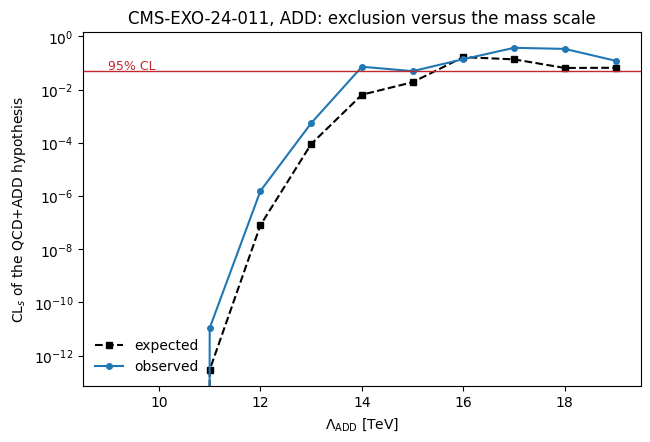

observed 95% CL lower limit on Lambda: 13.92 TeV
expected 95% CL lower limit on Lambda: 15.45 TeV

CMS quotes its limits from a toy-based CLs and its own scan in Lambda;
what is reproduced here is the model, and an asymptotic limit computed from it.


In [26]:
if CMS_AVAILABLE and ADD:
    ordered = sorted(scan)  # the cards come back in file-name order, 9 TeV last
    scales = np.array([row[0] for row in ordered])
    observed_cls = 1.0 - np.array([row[1] for row in ordered])
    expected_cls = 1.0 - np.array([row[2] for row in ordered])

    def crossing(values):
        """First scale, from below, at which CLs rises through 0.05."""
        above = np.flatnonzero(values > 0.05)
        if above.size == 0:
            return float("nan")
        index = int(above[0])
        if index == 0:
            return float("nan")
        low, high = scales[index - 1], scales[index]
        logs = np.log(np.clip(values[index - 1 : index + 1], 1e-300, None))
        return float(low + (high - low) * (np.log(0.05) - logs[0]) / (logs[1] - logs[0]))

    fig, axes = plt.subplots(figsize=(7.2, 4.6))
    axes.plot(
        scales,
        expected_cls,
        color="black",
        linestyle="--",
        marker="s",
        markersize=4,
        label="expected",
    )
    axes.plot(
        scales, observed_cls, color="#1f77b4", marker="o", markersize=4, label="observed"
    )
    axes.axhline(0.05, color="#c1272d", lw=1.0)
    axes.text(scales[0], 0.058, r"95% CL", color="#c1272d", fontsize=9)
    axes.set_yscale("log")
    axes.set_xlabel(r"$\Lambda_{\mathrm{ADD}}$ [TeV]")
    axes.set_ylabel(r"$\mathrm{CL}_s$ of the QCD+ADD hypothesis")
    axes.set_title("CMS-EXO-24-011, ADD: exclusion versus the mass scale")
    axes.legend(frameon=False)
    plt.show()

    print("observed 95%% CL lower limit on Lambda: %.2f TeV" % crossing(observed_cls))
    print("expected 95%% CL lower limit on Lambda: %.2f TeV" % crossing(expected_cls))
    print()
    print("CMS quotes its limits from a toy-based CLs and its own scan in Lambda;")
    print(
        "what is reproduced here is the model, and an asymptotic limit computed from it."
    )

### Reinterpretation

The last thing the plug-in has to do is attach a signal of someone else's making to a
published card. The two signal processes of the card are stripped, which leaves the
negligible `QCD` dummy as the only background, and an excess of one's own is attached to
the highest mass channel. The card is rewritten and handed back to `combine`, so the
reinterpreted model is built by exactly the same code as the published one.

In [27]:
if CMS_AVAILABLE:
    injected = [4.0, 3.0, 2.0, 1.0, 1.0] + [0.0] * 7

    patched, _ = patch_datacard(
        REFERENCE, injections={"bin7": injected}, strip_signal=True
    )
    print("the rewritten card, without its shapes block:")
    print(
        "\n".join(line for line in patched.splitlines() if not line.startswith("shapes"))[
            :1200
        ]
    )

the rewritten card, without its shapes block:

imax *
jmax *
kmax *
-----------

-----------
bin bin0 bin1 bin2 bin3 bin4 bin5 bin6 bin7 
observation 1363868.140625 283202.833984375 68233.1220703125 17732.21337890625 5040.483581542969 1423.0624694824219 433.0 50.0 
-----------
bin bin0 bin1 bin2 bin3 bin4 bin5 bin6 bin7 bin7
process QCD QCD QCD QCD QCD QCD QCD QCD spey_signal
process 1 1 1 1 1 1 1 1 0
rate 1.2557568530519367e-18 2.6741491146138223e-19 6.498432270309237e-20 1.7155337052721505e-20 4.694058958303398e-21 1.3177479217847972e-21 4.439880546726905e-22 5.406579225195065e-23 -1
-----------

model shape - - - - - - - - -
JERtail shape - - - - - - - - -
sim shape - - - - - - - - -
model3000 shape - - - - - - - - -
model3600 shape - - - - - - - - -
model4200 shape - - - - - - - - -
model4800 shape - - - - - - - - -
model5400 shape - - - - - - - - -
model6000 shape - - - - - - - - -
model7000 shape - - - - - - - - -
JERtail3000 shape - - - - - - - - -
JERtail3600 shape - - - - - - 

In [28]:
if CMS_AVAILABLE:
    reinterpreted = spey.get_backend("root.cms-combine")(
        datacard=REFERENCE,
        signal_yields={"bin7": injected},
        strip_existing_signal=True,
        analysis="reinterpretation",
    )
    background, signal = reinterpreted.backend._background_and_signal()
    print("is_alive            :", reinterpreted.backend.is_alive)
    print("injected signal     :", np.round(signal[84:89], 6))
    print("background there    :", np.round(background[84:89], 6))
    print("signal elsewhere    : %.2e" % float(np.max(np.abs(signal[:84]))))
    print()
    with disable_logging():
        print(
            "95%% CL upper limit on the injected signal strength: %.4f"
            % reinterpreted.poi_upper_limit()
        )

is_alive            : True
injected signal     : [4. 3. 2. 1. 1.]
background there    : [0. 0. 0. 0. 0.]
signal elsewhere    : 0.00e+00



95% CL upper limit on the injected signal strength: 5.7001


---
## Summary

| what | against what | agreement |
| --- | --- | --- |
| counting card, no systematics | `default.poisson` | machine precision |
| `autoMCStats`, Gaussian mode | `default.uncorrelated_background` | minimiser tolerance |
| `lnN` | `pyhf` `normsys`, through `spey-pyhf` | minimiser tolerance |
| yield-preserving `shape` | `HistFactory` `HistoSys`, through `root.roofit` | machine precision |
| Asimov data, bins and auxiliary | `default.uncorrelated_background` | machine precision |
| $t_\mu$ over 2000 toys | `spey` and `pyhf` on the same toys | minimiser tolerance |
| expected and observed $\mathrm{CL}_s$ | `spey` and `pyhf` | minimiser tolerance |
| CMS-EXO-24-011, structure and yields | the datacard itself | machine precision |
| CMS-EXO-24-011, profile likelihood $-2\Delta\log\mathcal{L}(x)$ | `text2workspace.py --no-optimize-pdfs` + `RooFit` | $8\times10^{-3}$, from the widened auxiliary ranges |
| CMS-EXO-24-011, $\mathrm{CL}_s$ and upper limits | `text2workspace.py --no-optimize-pdfs` + `RooStats` | $\mathrm{CL}_s$ to $10^{-3}$, limits to $10^{-3}$ |
| CMS-EXO-24-011, limit on $\Lambda$ | — | the scan above |

What is *not* being validated here is `combine`'s own arithmetic: the plug-in does not
reimplement it, it calls it. The comparisons above test that the model `combine` is given
is the model the datacard describes, that the workspace it returns is read correctly —
parameters, data, auxiliary measurements, Asimov datasets — and that a card rewritten to
carry a different signal still describes what was asked for.

Two differences from a plain `combine` run are worth remembering:

* the plug-in asks `combine` for plain `RooGaussian` constraint terms rather than its
  optimised `SimpleGaussianConstraint`, so that absolute log-likelihood values are in the
  same normalisation as every other `spey` backend. No likelihood ratio changes.
* a card without `shapes` directives is given one-bin templates before it is compiled,
  because `combine` builds a counting experiment as a product of `RooPoisson` terms over
  plain variables rather than as a binned model. The likelihood is the same product of
  Poisson terms either way.